# 현실의 데이터 13: 연결 예측: 사람 · 친구 추천

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/13_link_prediction.ipynb)

**분야**: 플랫폼 · 서비스 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 링크 예측 (Link Prediction) · 친구 · 연결 추천 · 그래프 데이터

> 연구기관 1,005명이 주고받은 이메일 연결망. 아직 연결 안 된 두 사람, 곧 연락하게 될까?

**데이터**: email-Eu-core (약 0.1MB). SNAP, Stanford (Leskovec, Kleinberg & Faloutsos, 2007; Yin et al., 2017). 유럽 한 연구기관 구성원 1,005명 사이의 이메일 연결 25,571개 + 소속 부서 42개.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 두 사람의 쌍 |
| ② 입력 X | 지금까지의 연결망 (공통 지인 수, 같은 부서인가 …) |
| ③ 출력 y | 둘이 연결되는가 |
| ④ 평가지표 | ROC-AUC (진짜 연결을 더 높게 매겼나) |
| ⑤ 기준선 | 무작위 점수 (AUC 0.5) |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Liben-Nowell & Kleinberg (2007) The link-prediction problem for social networks, JASIST](https://doi.org/10.1002/asi.20591)
- [Yin, Benson, Leskovec & Gleich (2017) Local Higher-Order Graph Clustering, KDD (email-Eu-core)](https://doi.org/10.1145/3097983.3098069)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

한 줄 = '이 사람이 저 사람에게 메일을 보낸 적 있다'. 방향은 무시하고 '연결' 로 본다.

In [2]:
import gzip
edges = pd.read_csv(download("https://snap.stanford.edu/data/email-Eu-core.txt.gz", "data/email-Eu-core.txt.gz"), sep=" ", header=None, names=["a", "b"])
dept = pd.read_csv(download("https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz", "data/email-dept.txt.gz"), sep=" ", header=None, names=["person", "dept"])
edges = edges[edges["a"] != edges["b"]]
pairs = {tuple(sorted(p)) for p in edges[["a", "b"]].itertuples(index=False)}
n = dept["person"].max() + 1
print("people:", n, " undirected links:", len(pairs), " departments:", dept["dept"].nunique())

people: 1005  undirected links: 16064  departments: 42


## 열어 보기

사람마다 연결 수 (차수) 는? 몇 명에게 몰려 있을까?

links per person: median 21 max 345 | people with 0 links: 19
share of all possible pairs that are linked: 3.18%


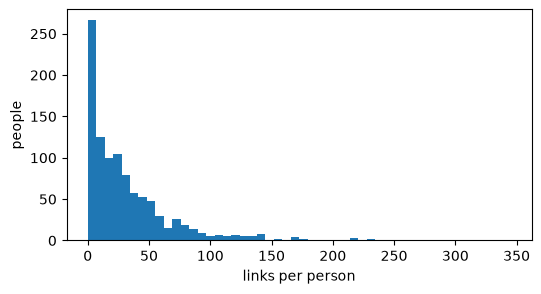

In [3]:
degree = np.zeros(n, dtype=int)
for a, b in pairs:
    degree[a] += 1; degree[b] += 1
print("links per person: median", int(np.median(degree)), "max", degree.max(), "| people with 0 links:", (degree == 0).sum())
print(f"share of all possible pairs that are linked: {len(pairs) / (n * (n - 1) / 2):.2%}")
plt.figure(figsize=(6, 3)); plt.hist(degree, bins=50); plt.xlabel("links per person"); plt.ylabel("people"); plt.show()

## 문제 하나 골라 보기: 두 사람 → 연결될까

연결 10% 를 **숨겨서** 시험 문제로 쓴다 (= 미래에 생길 연결). 같은 수만큼 연결 안 된 쌍도 섞는다. 남은 90% 연결망만 보고 점수를 매긴다:
- **공통 지인 수**: 둘 다 아는 사람이 많을수록 연결될 것 같다
- **같은 부서인가**
- 기준선: 무작위 점수

In [4]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(0)
all_pairs = np.array(sorted(pairs))
hidden_idx = rng.choice(len(all_pairs), size=len(all_pairs) // 10, replace=False)
hidden = all_pairs[hidden_idx]
known = {tuple(p) for k, p in enumerate(all_pairs) if k not in set(hidden_idx)}
neighbors = [set() for _ in range(n)]
for a, b in known:
    neighbors[a].add(b); neighbors[b].add(a)

non_links = []
while len(non_links) < len(hidden):
    a, b = sorted(rng.integers(0, n, 2))
    if a != b and (a, b) not in pairs:
        non_links.append((a, b))
test_pairs = np.vstack([hidden, np.array(non_links)])
y = np.r_[np.ones(len(hidden)), np.zeros(len(non_links))]

dept_of = dept.set_index("person")["dept"].to_dict()
common = np.array([len(neighbors[a] & neighbors[b]) for a, b in test_pairs])
same_dept = np.array([dept_of[a] == dept_of[b] for a, b in test_pairs], dtype=float)
print(f"random score           : AUC {roc_auc_score(y, rng.random(len(y))):.2f}")
print(f"same department        : AUC {roc_auc_score(y, same_dept):.2f}")
print(f"number of common friends: AUC {roc_auc_score(y, common):.2f}")

random score           : AUC 0.49
same department        : AUC 0.65
number of common friends: AUC 0.94


**ROC-AUC 읽는 법**: 진짜 연결 하나와 연결 아닌 쌍 하나를 무작위로 뽑았을 때, 진짜 쪽 점수가 더 높을 확률. 0.5 = 동전 던지기, 1 = 완벽.

## 다른 문제로 바꿔 보기

- **친구 추천**: 실제 서비스는 '이 쌍이 연결될까' 가 아니라 '이 사람에게 보여 줄 5명' 을 고른다. 한 행 = 사람, 지표 = 추천 5명 중 실제로 연결된 수.
- **시간**: 이 데이터의 시간 정보가 있는 판 (email-Eu-core-temporal) 을 쓰면 '과거 연결로 미래 연결 맞히기' 를 정직하게 할 수 있다.
- 그래프 신경망 (13주차 GCN) 은 공통 지인 같은 규칙을 직접 정하지 않고 배운다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |